In [2]:
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split

# Binary
Xb, yb = load_breast_cancer(return_X_y=True)

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    Xb, yb, test_size=0.2, random_state=42, stratify=yb
)

# Multiclass
Xm, ym = load_iris(return_X_y=True)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    Xm, ym, test_size=0.2, random_state=42, stratify=ym
)

In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_b, y_train_b)

y_pred = model.predict(X_test_b)
y_prob = model.predict_proba(X_test_b)

print(y_pred[:5])
print(y_prob[:2])

[0 1 0 1 0]
[[1.00000000e+00 3.22096111e-12]
 [2.18378038e-04 9.99781622e-01]]


/Users/harshutkarshmishra/Downloads/VS Code/AI_Data_Revision/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [5]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_m, y_train_m)

y_pred = model.predict(X_test_m)
y_prob = model.predict_proba(X_test_m)

print(y_pred[:5])
print(y_prob[:2])

[0 2 1 1 0]
[[9.85319862e-01 1.46800913e-02 4.62309733e-08]
 [1.37591790e-03 3.90976997e-01 6.07647085e-01]]


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X, _ = make_blobs(
    n_samples=500,
    centers=4,
    n_features=2,
    cluster_std=1.5,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Income", "Spending"]
)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K={k}, Silhouette={score:.4f}")

Matplotlib is building the font cache; this may take a moment.


K=2, Silhouette=0.5315
K=3, Silhouette=0.6956
K=4, Silhouette=0.6941
K=5, Silhouette=0.5939
K=6, Silhouette=0.5149
K=7, Silhouette=0.4049
K=8, Silhouette=0.3418
K=9, Silhouette=0.3525
K=10, Silhouette=0.3516


/var/folders/f3/1c9kr78x4jg4mf1qj3v0txjw0000gn/T/ipykernel_5729/1444544122.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries, autolag='AIC')


--- Augmented Dickey-Fuller Test ---
ADF Statistic: 2.4697
p-value: 0.9990
Result: Data is Non-Stationary (Fail to reject H0)


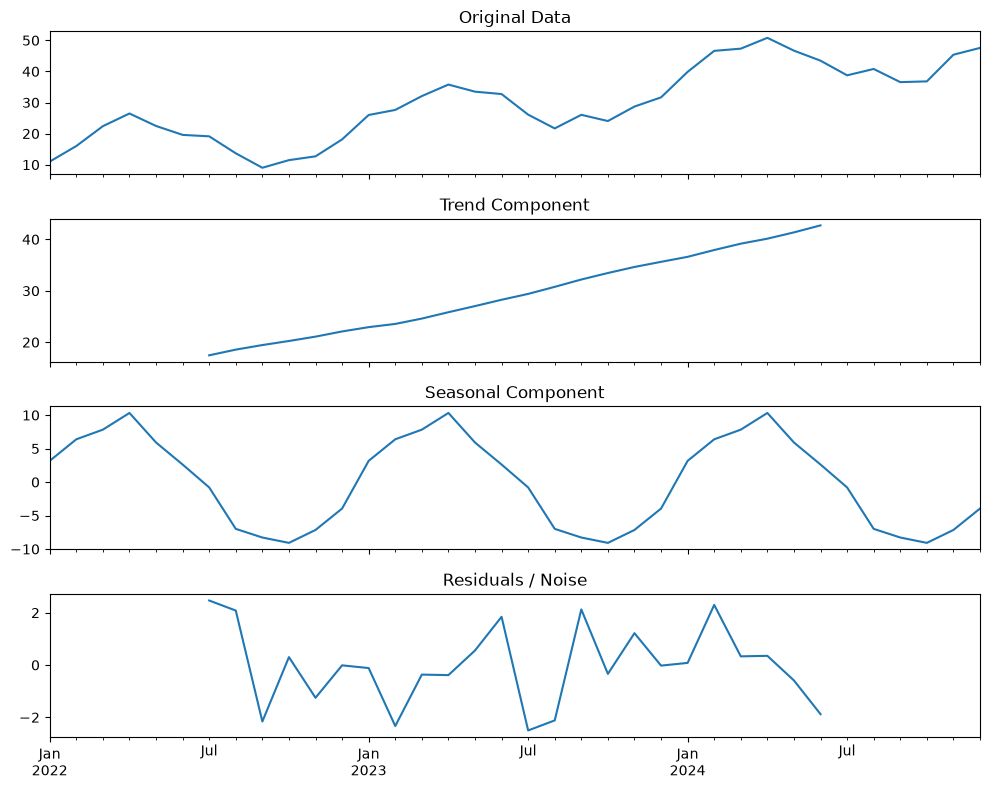

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Create a dummy monthly time series with a trend and seasonality
np.random.seed(42)
dates = pd.date_range(start='2022-01-01', periods=36, freq='ME')
trend = np.linspace(10, 50, 36)
seasonality = 10 * np.sin(np.linspace(0, 3 * 2 * np.pi, 36))
noise = np.random.normal(0, 2, 36)
sales = trend + seasonality + noise

df = pd.DataFrame({'Sales': sales}, index=dates)

# 2. Check Stationarity using Augmented Dickey-Fuller Test
def test_stationarity(timeseries):
    result = adfuller(timeseries, autolag='AIC')
    print("--- Augmented Dickey-Fuller Test ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    if result[1] <= 0.05:
        print("Result: Data is Stationary (Reject H0)")
    else:
        print("Result: Data is Non-Stationary (Fail to reject H0)")

test_stationarity(df['Sales'])

# 3. Decompose to see Trend and Seasonality
decomposition = seasonal_decompose(df['Sales'], model='additive', period=12)

# Plotting the components
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
decomposition.observed.plot(ax=axes[0], title='Original Data')
decomposition.trend.plot(ax=axes[1], title='Trend Component')
decomposition.seasonal.plot(ax=axes[2], title='Seasonal Component')
decomposition.resid.plot(ax=axes[3], title='Residuals / Noise')
plt.tight_layout()
plt.show()

/var/folders/f3/1c9kr78x4jg4mf1qj3v0txjw0000gn/T/ipykernel_5729/1526521216.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df['Sales'])
/Users/harshutkarshmishra/Downloads/VS Code/AI_Data_Revision/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


ADF p-value: 0.9970 (Non-stationary, hence differencing is needed)

Ljung-Box Test p-value: 0.0032
Result: Residuals still contain patterns. The model missed something.


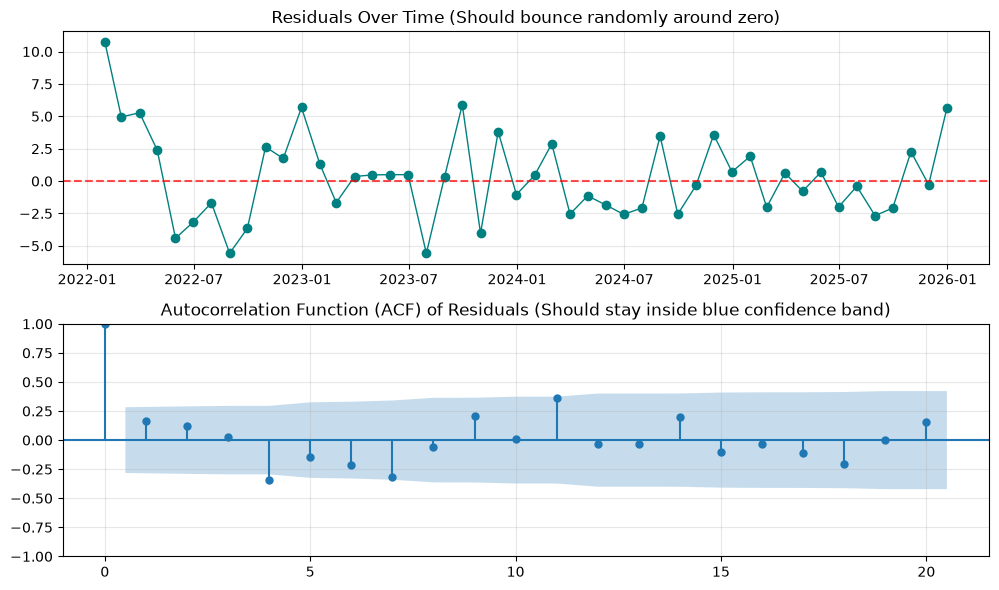

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. Generate a synthetic monthly time series with trend and 12-month seasonality
np.random.seed(42)
dates = pd.date_range(start='2022-01-01', periods=48, freq='ME')
trend = np.linspace(10, 60, 48)
seasonality = 12 * np.sin(np.linspace(0, 4 * 2 * np.pi, 48))
noise = np.random.normal(0, 1.5, 48)
sales = trend + seasonality + noise

df = pd.DataFrame({'Sales': sales}, index=dates)

# 2. Check Stationarity using Augmented Dickey-Fuller Test
adf_result = adfuller(df['Sales'])
print(f"ADF p-value: {adf_result[1]:.4f} (Non-stationary, hence differencing is needed)")

# 3. Fit a SARIMA Model
# order=(1,1,1) handles non-seasonal trend/differencing
# seasonal_order=(1,1,1,12) handles the 12-month repeating seasonal cycle
model = SARIMAX(df['Sales'], 
                order=(1, 1, 1), 
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False, 
                enforce_invertibility=False)
results = model.fit(disp=False)

# 4. Extract Residuals (Leftover errors after model removes trend & season)
residuals = results.resid

# 5. Run Ljung-Box Test on Residuals
# H0: Residuals are random white noise (no patterns left)
lb_test = acorr_ljungbox(residuals, lags=[12], return_df=True)
p_val = lb_test['lb_pvalue'].values[0]

print(f"\nLjung-Box Test p-value: {p_val:.4f}")
if p_val > 0.05:
    print("Result: Residuals are white noise. The model captured all patterns!")
else:
    print("Result: Residuals still contain patterns. The model missed something.")

# 6. Visual Diagnostics (Time plot & ACF of residuals)
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Time plot of residuals
axes[0].plot(residuals, color='teal', marker='o', linestyle='-', linewidth=1)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.7)
axes[0].set_title("Residuals Over Time (Should bounce randomly around zero)")
axes[0].grid(True, alpha=0.3)

# ACF plot of residuals
plot_acf(residuals, ax=axes[1], lags=20)
axes[1].set_title("Autocorrelation Function (ACF) of Residuals (Should stay inside blue confidence band)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
import numpy as np
from pmdarima import auto_arima

# 1. Generate sample data (same monthly trend + seasonality)
np.random.seed(42)
dates = pd.date_range(start='2022-01-01', periods=48, freq='ME')
sales = np.linspace(10, 60, 48) + 12 * np.sin(np.linspace(0, 4 * 2 * np.pi, 48)) + np.random.normal(0, 1.5, 48)
df = pd.DataFrame({'Sales': sales}, index=dates)

# 2. Run Auto-ARIMA to find optimal parameters automatically
# m=12 specifies monthly seasonality cycle
# seasonal=True enables SARIMA search
# stepwise=True speeds up the search drastically
auto_model = auto_arima(df['Sales'], 
                        seasonal=True, 
                        m=12, 
                        trace=True, 
                        error_action='ignore', 
                        suppress_warnings=True, 
                        stepwise=True)

# 3. Print the best model summary and selected orders
print("\n--- Optimal Model Found ---")
print(auto_model.summary())

# Extract exact orders found by auto_arima
print(f"\nBest Non-Seasonal Order (p, d, q): {auto_model.order}")
print(f"Best Seasonal Order (P, D, Q, m): {auto_model.seasonal_order}")

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[12] intercept   : AIC=176.373, Time=0.29 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=168.885, Time=0.01 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=174.211, Time=0.18 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=169.729, Time=0.03 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=287.226, Time=0.01 sec
 ARIMA(0,0,0)(1,1,0)[12] intercept   : AIC=169.674, Time=0.13 sec
 ARIMA(0,0,0)(0,1,1)[12] intercept   : AIC=169.948, Time=0.02 sec
 ARIMA(0,0,0)(1,1,1)[12] intercept   : AIC=170.967, Time=0.14 sec
 ARIMA(1,0,0)(0,1,0)[12] intercept   : AIC=169.530, Time=0.03 sec
 ARIMA(0,0,1)(0,1,0)[12] intercept   : AIC=169.628, Time=0.01 sec
 ARIMA(1,0,1)(0,1,0)[12] intercept   : AIC=171.497, Time=0.05 sec

Best model:  ARIMA(0,0,0)(0,1,0)[12] intercept
Total fit time: 0.916 seconds

--- Optimal Model Found ---
                                SARIMAX Results                                 
Dep. Variable:                        y   N